In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("harshitshankhdhar/imdb-dataset-of-top-1000-movies-and-tv-shows")

print("Path to dataset files:", path)

c:\Users\moham\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 175k/175k [00:00<00:00, 596kB/s]

Extracting files...
Path to dataset files: C:\Users\moham\.cache\kagglehub\datasets\harshitshankhdhar\imdb-dataset-of-top-1000-movies-and-tv-shows\versions\1


In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [17]:
df = pd.read_csv(r"C:\Users\moham\.cache\kagglehub\datasets\harshitshankhdhar\imdb-dataset-of-top-1000-movies-and-tv-shows\versions\1\imdb_top_1000.csv")
df.head()

,Poster_Link,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Overview,Meta_score,Director,Star1,Star2,Star3,Star4,No_of_Votes,Gross
0,https://m.media-amazon.com/images/M/MV5BMDFkYT...,The Shawshank Redemption,1994,A,142 min,Drama,9.3,Two imprisoned men bond over a number of years...,80.0,Frank Darabont,Tim Robbins,Morgan Freeman,Bob Gunton,William Sadler,2343110,"28,341,469"
1,https://m.media-amazon.com/images/M/MV5BM2MyNj...,The Godfather,1972,A,175 min,"Crime, Drama",9.2,An organized crime dynasty's aging patriarch t...,100.0,Francis Ford Coppola,Marlon Brando,Al Pacino,James Caan,Diane Keaton,1620367,"134,966,411"
2,https://m.media-amazon.com/images/M/MV5BMTMxNT...,The Dark Knight,2008,UA,152 min,"Action, Crime, Drama",9.0,When the menace known as the Joker wreaks havo...,84.0,Christopher Nolan,Christian Bale,Heath Ledger,Aaron Eckhart,Michael Caine,2303232,"534,858,444"
3,https://m.media-amazon.com/images/M/MV5BMWMwMG...,The Godfather: Part II,1974,A,202 min,"Crime, Drama",9.0,The early life and career of Vito Corleone in ...,90.0,Francis Ford Coppola,Al Pacino,Robert De Niro,Robert Duvall,Diane Keaton,1129952,"57,300,000"
4,https://m.media-amazon.com/images/M/MV5BMWU4N2...,12 Angry Men,1957,U,96 min,"Crime, Drama",9.0,A jury holdout attempts to prevent a miscarria...,96.0,Sidney Lumet,Henry Fonda,Lee J. Cobb,Martin Balsam,John Fiedler,689845,"4,360,000"


In [18]:
df.isna().sum()

Poster_Link        0
Series_Title       0
Released_Year      0
Certificate      101
Runtime            0
Genre              0
IMDB_Rating        0
Overview           0
Meta_score       157
Director           0
Star1              0
Star2              0
Star3              0
Star4              0
No_of_Votes        0
Gross            169
dtype: int64

In [19]:
df["Certificate"].value_counts()

Certificate
U           234
A           197
UA          175
R           146
PG-13        43
PG           37
Passed       34
G            12
Approved     11
TV-PG         3
GP            2
TV-14         1
16            1
TV-MA         1
Unrated       1
U/A           1
Name: count, dtype: int64

In [20]:
df['Certificate'] = df['Certificate'].replace({
    'U/A': 'UA'
})

In [21]:
df['Certificate'] = df['Certificate'].fillna(
    df['Certificate'].mode()[0]
)

In [22]:
df.isna().sum()

Poster_Link        0
Series_Title       0
Released_Year      0
Certificate        0
Runtime            0
Genre              0
IMDB_Rating        0
Overview           0
Meta_score       157
Director           0
Star1              0
Star2              0
Star3              0
Star4              0
No_of_Votes        0
Gross            169
dtype: int64

In [23]:
df["Meta_score"].value_counts()

Meta_score
76.0    32
84.0    29
90.0    29
80.0    27
73.0    27
        ..
28.0     1
36.0     1
46.0     1
30.0     1
41.0     1
Name: count, Length: 63, dtype: int64

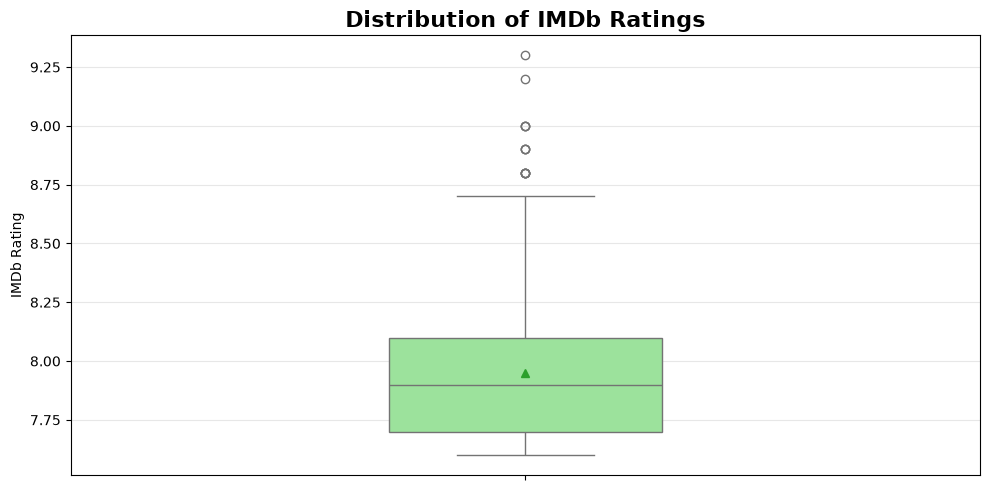

In [ ]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    y=df['IMDB_Rating'],
    color='lightgreen',
    width=0.3,
    showmeans=True
)

plt.title('Distribution of IMDb Ratings', fontsize=16, fontweight='bold')
plt.ylabel('IMDb Rating')

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


The boxplot shows that IMDb ratings are concentrated around 7.7–8.1, with a median of approximately 7.9. Several high-rating outliers appear above the upper whisker, indicating a small number of exceptionally highly rated movies. Overall, the dataset shows relatively high IMDb ratings with a narrow interquartile range.

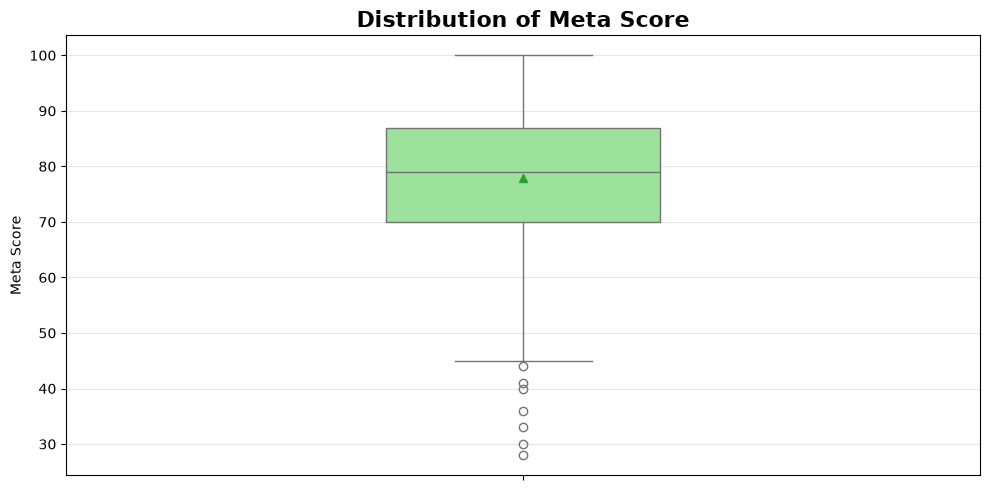

In [32]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    y=df['Meta_score'],
    color='lightgreen',
    width=0.3,
    showmeans=True
)

plt.title('Distribution of Meta Score', fontsize=16, fontweight='bold')
plt.ylabel('Meta Score')

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


In [35]:
df['Meta_score'] = df['Meta_score'].fillna(
    df['Meta_score'].median()
)

In [36]:
df.isnull().sum()

Poster_Link        0
Series_Title       0
Released_Year      0
Certificate        0
Runtime            0
Genre              0
IMDB_Rating        0
Overview           0
Meta_score         0
Director           0
Star1              0
Star2              0
Star3              0
Star4              0
No_of_Votes        0
Gross            169
dtype: int64

In [ ]:
df["Gross"]

0       28,341,469
1      134,966,411
2      534,858,444
3       57,300,000
4        4,360,000
          ...     
995            NaN
996            NaN
997     30,500,000
998            NaN
999            NaN
Name: Gross, Length: 1000, dtype: str

In [39]:
df['Gross'] = df['Gross'].str.replace(',', '', regex=False)

df['Gross'] = pd.to_numeric(df['Gross'], errors='coerce')

AttributeError: Can only use .str accessor with string values, not floating

In [40]:
df["Gross"]

0       28341469.0
1      134966411.0
2      534858444.0
3       57300000.0
4        4360000.0
          ...     
995            NaN
996            NaN
997     30500000.0
998            NaN
999            NaN
Name: Gross, Length: 1000, dtype: float64

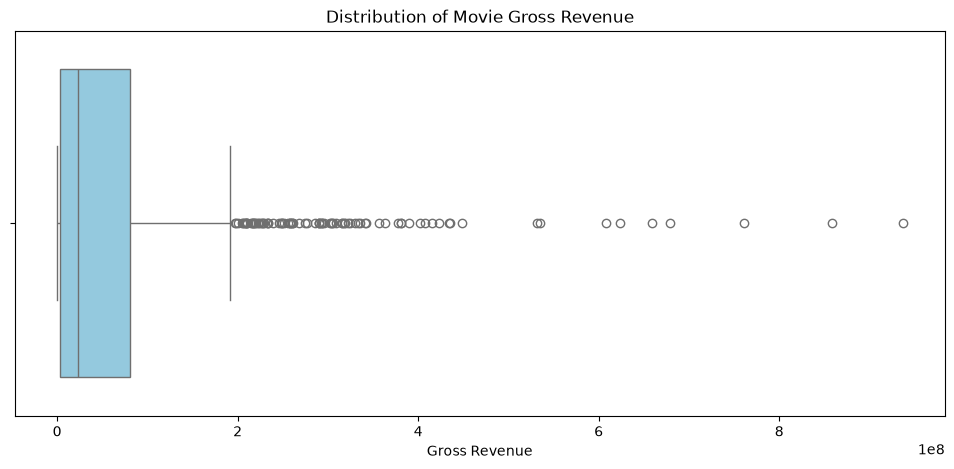

In [41]:
plt.figure(figsize=(12, 5))

sns.boxplot(x=df['Gross'], color='skyblue')

plt.title('Distribution of Movie Gross Revenue')
plt.xlabel('Gross Revenue')

plt.show()

In [43]:
df.shape


(1000, 16)

In [45]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Poster_Link    1000 non-null   str    
 1   Series_Title   1000 non-null   str    
 2   Released_Year  1000 non-null   str    
 3   Certificate    1000 non-null   str    
 4   Runtime        1000 non-null   str    
 5   Genre          1000 non-null   str    
 6   IMDB_Rating    1000 non-null   float64
 7   Overview       1000 non-null   str    
 8   Meta_score     1000 non-null   float64
 9   Director       1000 non-null   str    
 10  Star1          1000 non-null   str    
 11  Star2          1000 non-null   str    
 12  Star3          1000 non-null   str    
 13  Star4          1000 non-null   str    
 14  No_of_Votes    1000 non-null   int64  
 15  Gross          831 non-null    float64
dtypes: float64(3), int64(1), str(12)
memory usage: 125.1 KB


In [47]:
df.describe()

,IMDB_Rating,Meta_score,No_of_Votes,Gross
count,1000.000000,1000.000000,1.000000e+03,8.310000e+02
mean,7.949300,78.133000,2.736929e+05,6.803475e+07
std,0.275491,11.368225,3.273727e+05,1.097500e+08
min,7.600000,28.000000,2.508800e+04,1.305000e+03
25%,7.700000,72.000000,5.552625e+04,3.253559e+06
50%,7.900000,79.000000,1.385485e+05,2.353089e+07
75%,8.100000,85.250000,3.741612e+05,8.075089e+07
max,9.300000,100.000000,2.343110e+06,9.366622e+08


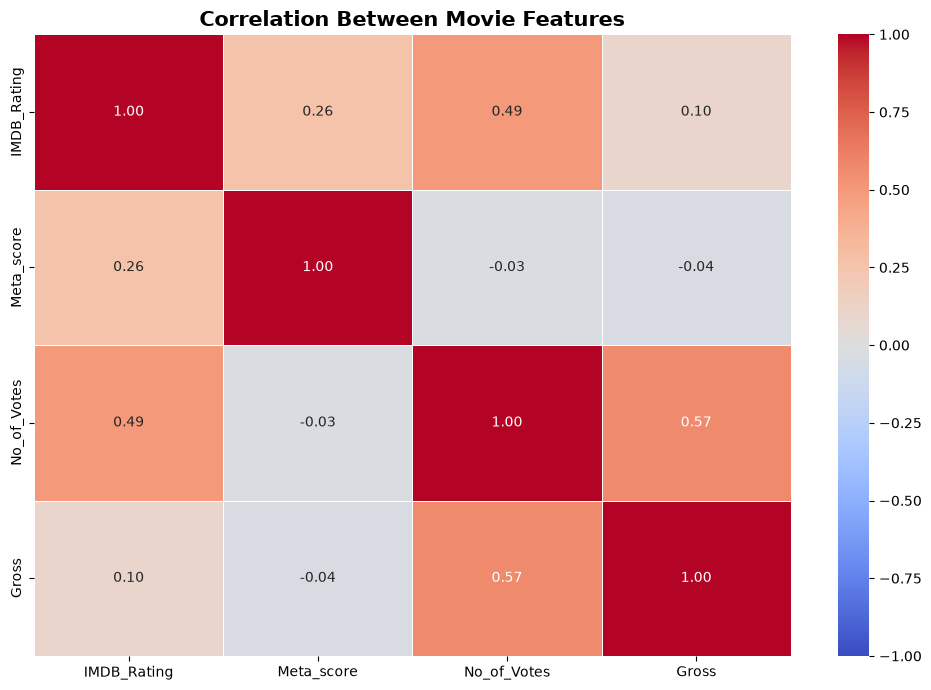

In [49]:
cols = [
    'IMDB_Rating',
    'Meta_score',
    'No_of_Votes',
    'Gross'
]

corr = df[cols].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title('Correlation Between Movie Features',
          fontsize=15, fontweight='bold')

plt.tight_layout()
plt.show()

Correlation analysis was performed to examine the relationships between IMDb ratings, Metascores, number of votes, and gross revenue.

The results revealed several interesting findings:

- **IMDb Rating & Meta_score (0.26):** A weak positive correlation, indicating limited agreement between audience and critics' ratings.
- **IMDb Rating & No_of_Votes (0.49):** A moderate positive correlation, suggesting that movies with more votes tend to have higher IMDb ratings.
- **IMDb Rating & Gross (0.10):** A very weak positive correlation, indicating that higher ratings do not necessarily lead to higher revenue.
- **Meta_score & Gross (-0.04):** Almost no linear correlation between critics' ratings and movie revenue.
- **No_of_Votes & Gross (0.57):** The strongest positive correlation, suggesting that movies with more audience engagement tend to generate higher revenue.
- **Meta_score & No_of_Votes (-0.03):** Almost no linear relationship between critics' ratings and audience voting activity.

**Conclusion:**

The analysis suggests that movie popularity, represented by the number of votes, has a stronger relationship with box office revenue than movie ratings. Additionally, audience ratings and critics' ratings show only a weak positive relationship.

In [61]:
df.describe(include='object')

C:\Users\moham\AppData\Local\Temp\ipykernel_6468\87514550.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,Poster_Link,Series_Title,Released_Year,Certificate,Runtime,Genre,Overview,Director,Star1,Star2,Star3,Star4
count,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000
unique,1000,999,100,15,140,202,1000,548,660,841,891,939
top,https://m.media-amazon.com/images/M/MV5BMDFkYT...,Drishyam,2014,U,130 min,Drama,Two imprisoned men bond over a number of years...,Alfred Hitchcock,Tom Hanks,Emma Watson,Rupert Grint,Michael Caine
freq,1,2,32,335,23,85,1,14,12,7,5,4


In [62]:
duplicates = df[df.duplicated(subset='Series_Title', keep=False)]

duplicates.sort_values('Series_Title')

,Poster_Link,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Overview,Meta_score,Director,Star1,Star2,Star3,Star4,No_of_Votes,Gross
87,https://m.media-amazon.com/images/M/MV5BYmY3Mz...,Drishyam,2013,U,160 min,"Crime, Drama, Thriller",8.3,A man goes to extreme lengths to save his fami...,79.0,Jeethu Joseph,Mohanlal,Meena,Asha Sharath,Ansiba,30722,NaN
136,https://m.media-amazon.com/images/M/MV5BYmJhZm...,Drishyam,2015,UA,163 min,"Crime, Drama, Mystery",8.2,Desperate measures are taken by a man who trie...,79.0,Nishikant Kamat,Ajay Devgn,Shriya Saran,Tabu,Rajat Kapoor,70367,739478.0


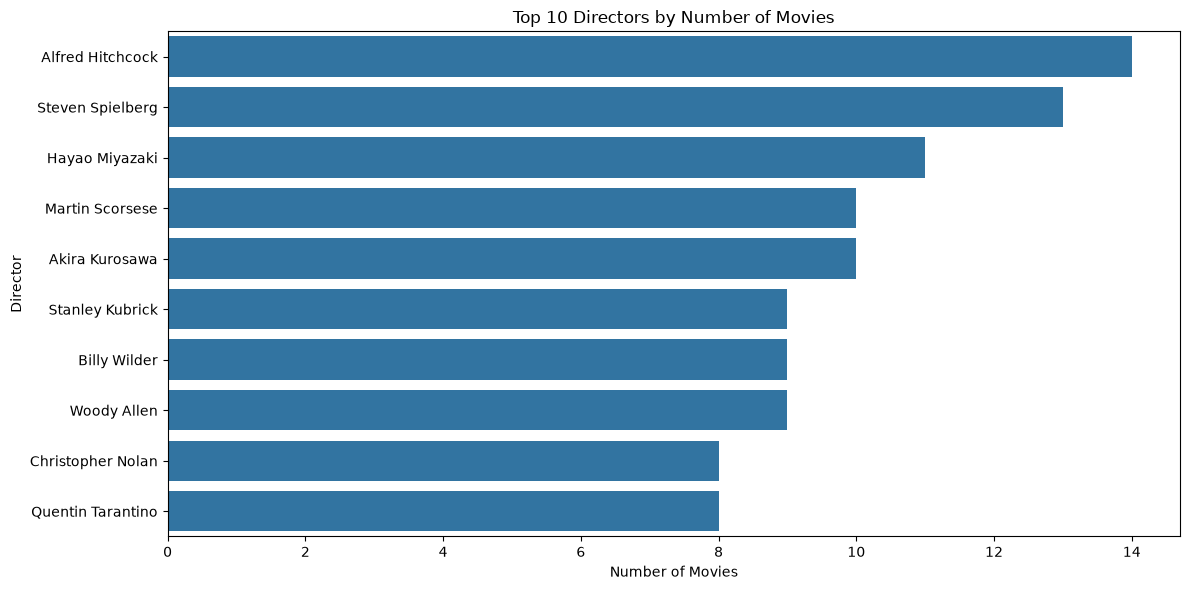

In [63]:
top_directors = df['Director'].value_counts().head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_directors.values,
    y=top_directors.index
)

plt.title('Top 10 Directors by Number of Movies')
plt.xlabel('Number of Movies')
plt.ylabel('Director')

plt.tight_layout()
plt.show()

### Top 10 Directors by Number of Movies

Alfred Hitchcock ranks first with 14 movies, followed by Steven Spielberg with 13 movies. Hayao Miyazaki comes third with 11 movies, while Martin Scorsese and Akira Kurosawa each have 10 movies.

The results show that Alfred Hitchcock and Steven Spielberg have the highest number of movies in the dataset among the top 10 directors.

In [83]:
top_directors = (
    df.groupby('Director')
    .agg(
        Avg_Rating=('IMDB_Rating', 'mean'),
        Movies_Count=('Series_Title', 'count')
    )
    .query('Movies_Count >= 3')
    .sort_values('Avg_Rating', ascending=False)
    .head(10)
)

print(top_directors)

                      Avg_Rating  Movies_Count
Director                                      
Christopher Nolan       8.462500             8
Peter Jackson           8.400000             5
Francis Ford Coppola    8.400000             5
Charles Chaplin         8.333333             6
Sergio Leone            8.266667             6
Stanley Kubrick         8.233333             9
Akira Kurosawa          8.220000            10
Frank Capra             8.200000             4
Quentin Tarantino       8.175000             8
Rajkumar Hirani         8.175000             4


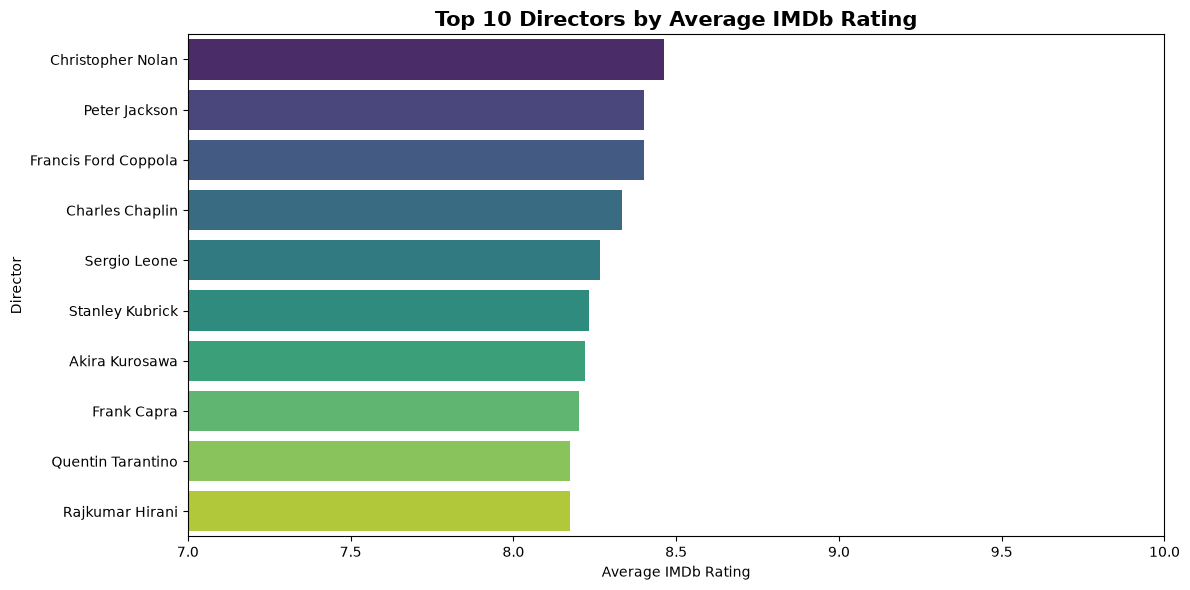

In [84]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_directors.reset_index(),
    x='Avg_Rating',
    y='Director',
    hue='Director',
    palette='viridis',
    legend=False
)

plt.title('Top 10 Directors by Average IMDb Rating',
          fontsize=15, fontweight='bold')

plt.xlabel('Average IMDb Rating')
plt.ylabel('Director')

plt.xlim(7, 10)
plt.tight_layout()
plt.show()

In [85]:
stars = df[['Star1', 'Star2', 'Star3', 'Star4']].melt(
    value_name='Actor'
)

top_actors = stars['Actor'].value_counts().head(10)

print(top_actors)

Actor
Robert De Niro       17
Tom Hanks            14
Al Pacino            13
Brad Pitt            12
Clint Eastwood       12
Christian Bale       11
Leonardo DiCaprio    11
Matt Damon           11
James Stewart        10
Humphrey Bogart       9
Name: count, dtype: int64


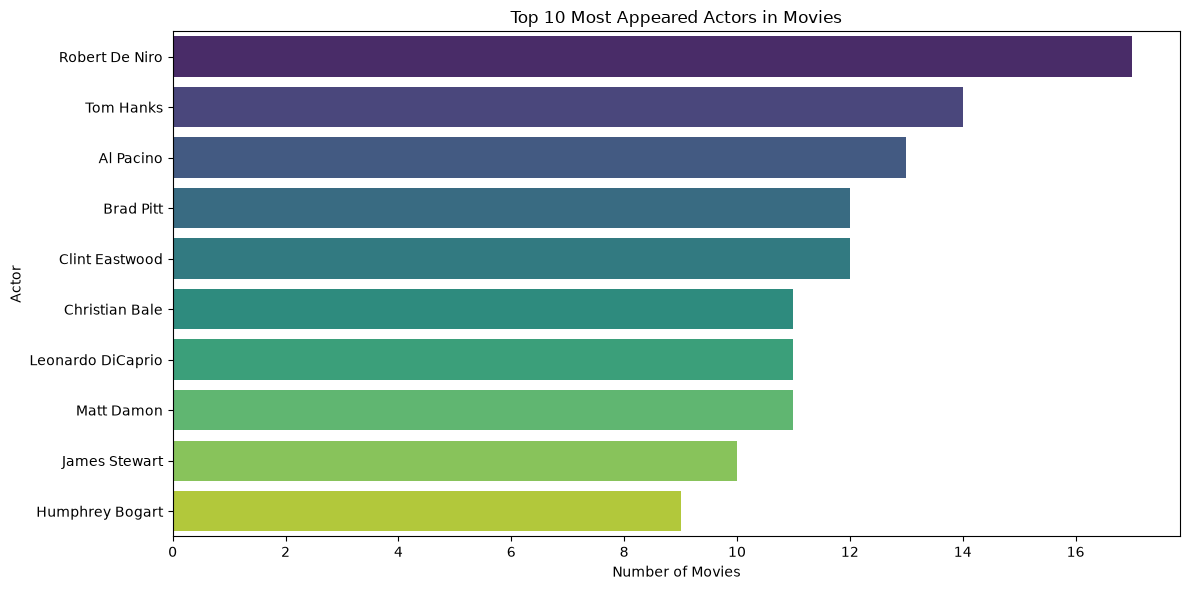

In [86]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_actors.values,
    y=top_actors.index,
    hue=top_actors.index,
    palette='viridis',
    legend=False
)

plt.title('Top 10 Most Appeared Actors in Movies')
plt.xlabel('Number of Movies')
plt.ylabel('Actor')
plt.tight_layout()
plt.show()

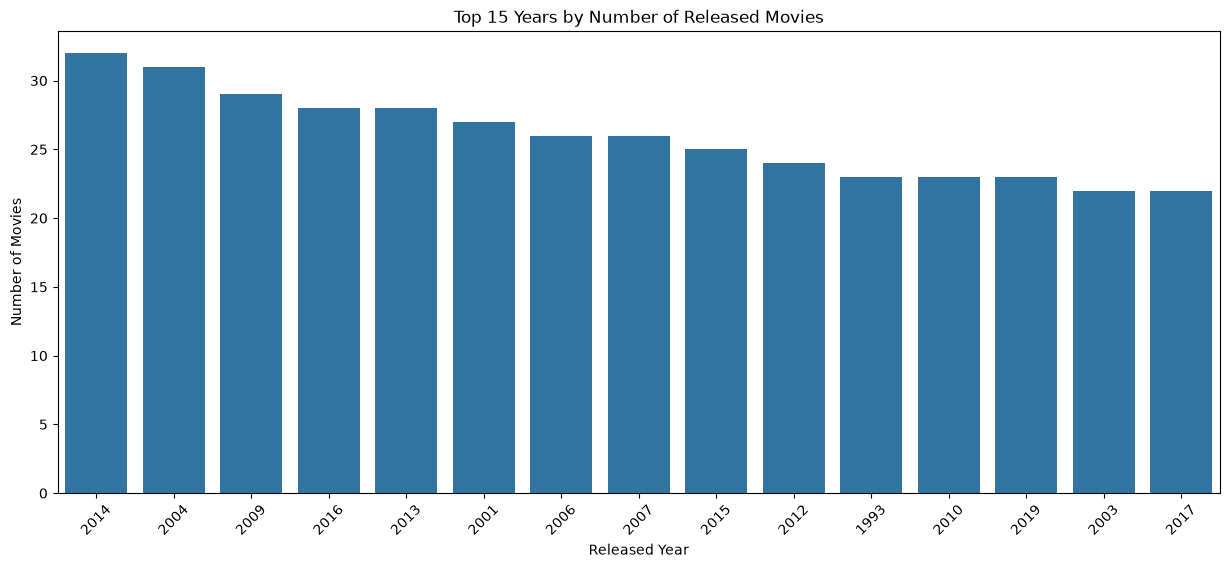

In [87]:
plt.figure(figsize=(15, 6))

sns.countplot(
    data=df,
    x='Released_Year',
    order=df['Released_Year'].value_counts().index[:15]
)

plt.title('Top 15 Years by Number of Released Movies')
plt.xlabel('Released Year')
plt.ylabel('Number of Movies')
plt.xticks(rotation=45)
plt.show()

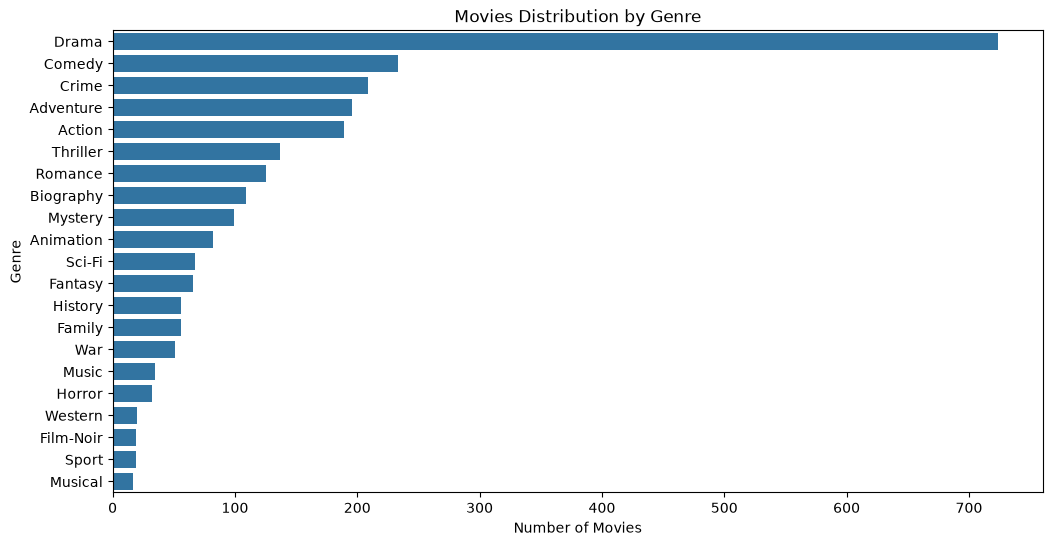

In [88]:
genre_counts = df['Genre'].str.split(', ').explode().value_counts()

plt.figure(figsize=(12, 6))

sns.barplot(
    x=genre_counts.values,
    y=genre_counts.index
)

plt.title('Movies Distribution by Genre')
plt.xlabel('Number of Movies')
plt.ylabel('Genre')
plt.show()

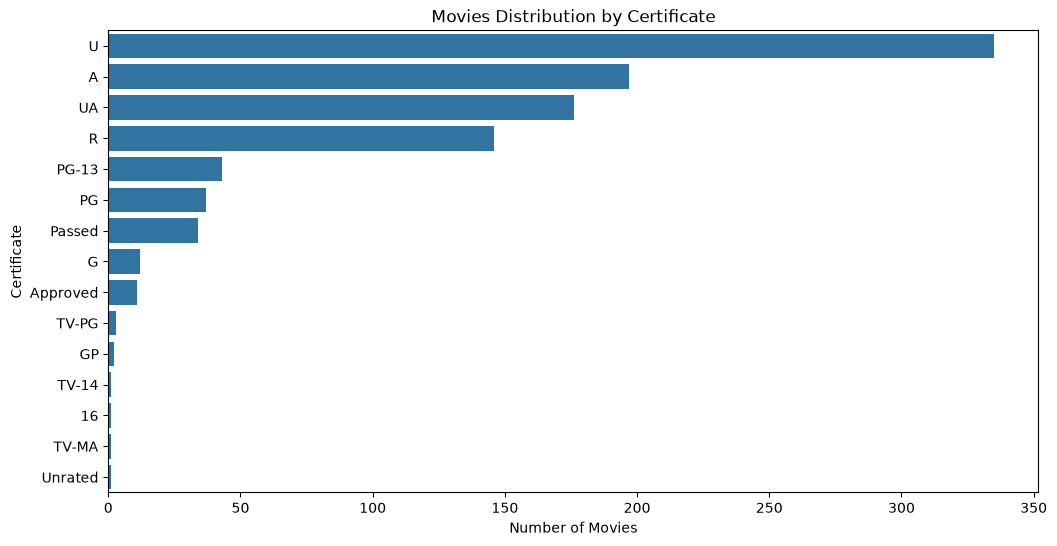

In [89]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y='Certificate',
    order=df['Certificate'].value_counts().index
)

plt.title('Movies Distribution by Certificate')
plt.xlabel('Number of Movies')
plt.ylabel('Certificate')
plt.show()

In [90]:
df['Runtime'] = df['Runtime'].str.replace(' min', '').astype(int)

AttributeError: Can only use .str accessor with string values, not integer

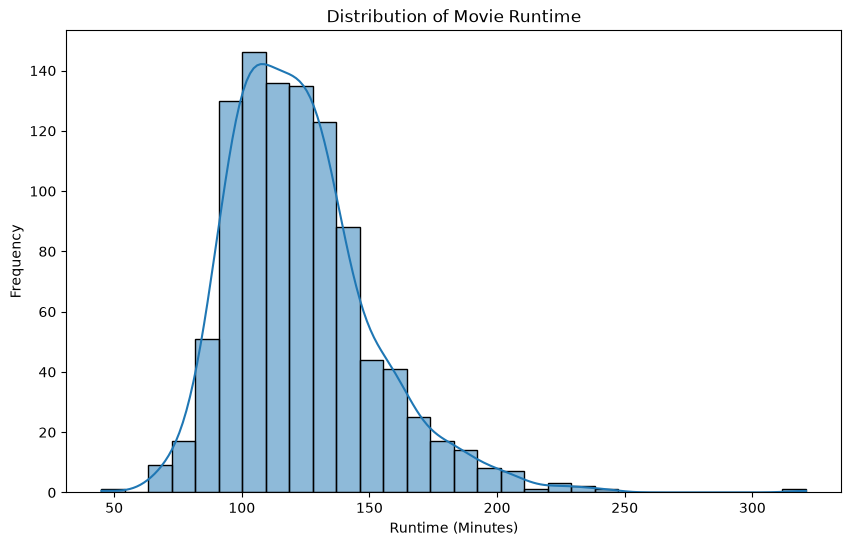

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='Runtime',
    bins=30,
    kde=True
)

plt.title('Distribution of Movie Runtime')
plt.xlabel('Runtime (Minutes)')
plt.ylabel('Frequency')
plt.show()

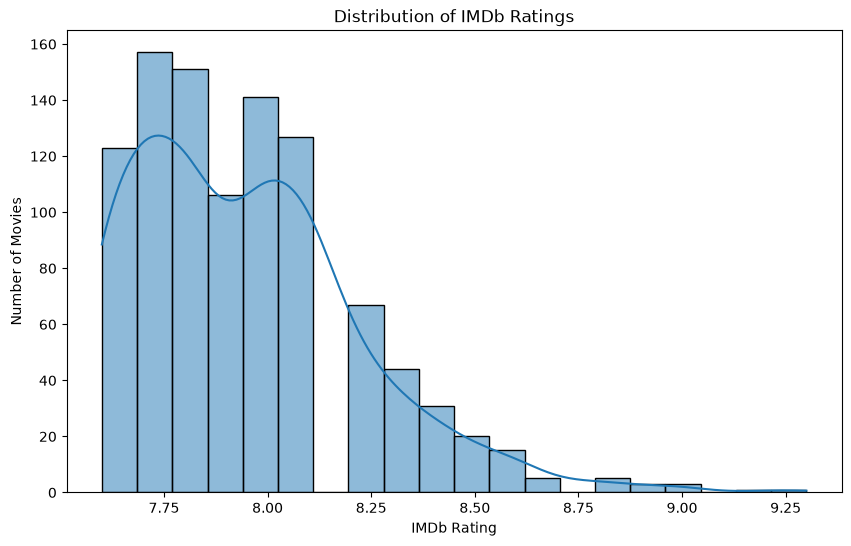

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(data=df, x='IMDB_Rating', bins=20, kde=True)

plt.title('Distribution of IMDb Ratings')
plt.xlabel('IMDb Rating')
plt.ylabel('Number of Movies')
plt.show()

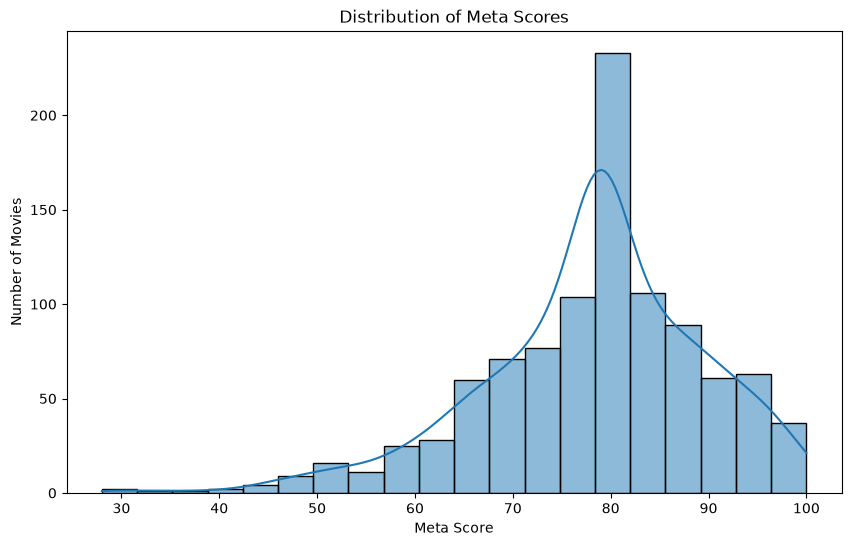

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(data=df, x='Meta_score', bins=20, kde=True)

plt.title('Distribution of Meta Scores')
plt.xlabel('Meta Score')
plt.ylabel('Number of Movies')
plt.show()

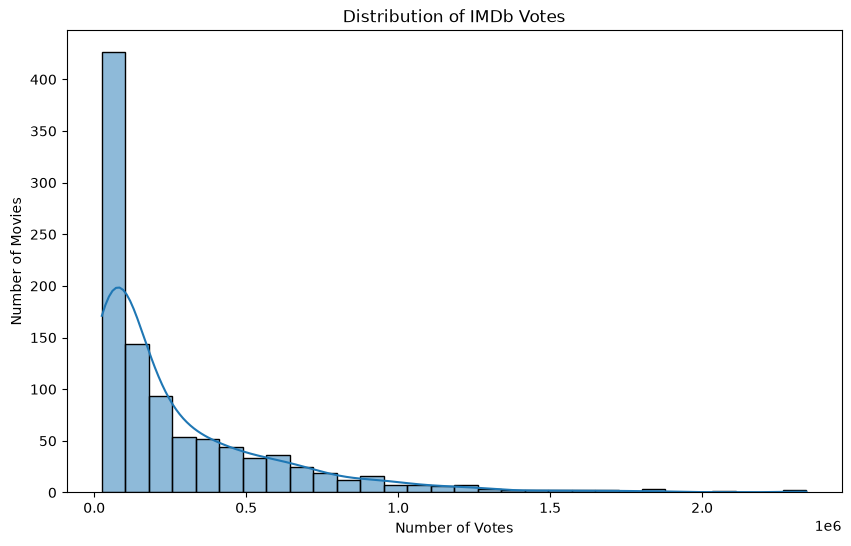

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(data=df, x='No_of_Votes', bins=30, kde=True)

plt.title('Distribution of IMDb Votes')
plt.xlabel('Number of Votes')
plt.ylabel('Number of Movies')
plt.show()

In [ ]:
df['Gross'] = pd.to_numeric(
    df['Gross'].astype(str).str.replace(',', '', regex=False),
    errors='coerce'
)

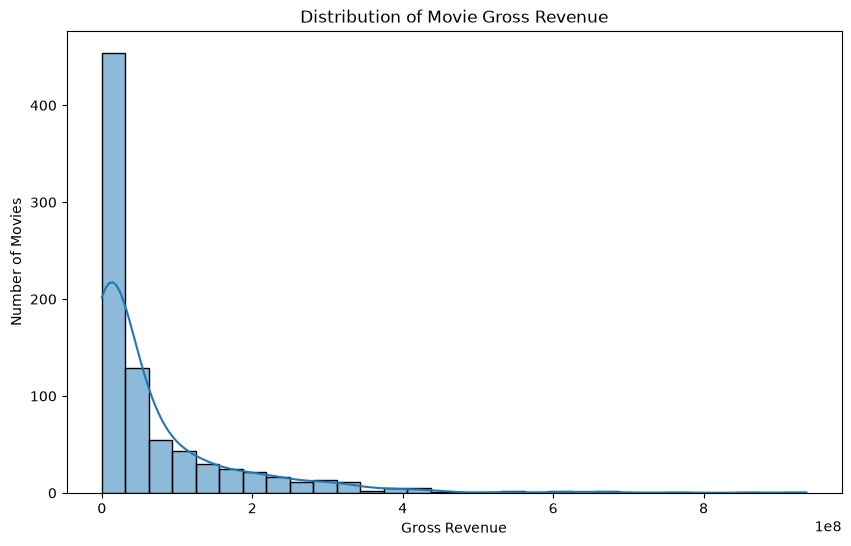

In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(data=df, x='Gross', bins=30, kde=True)

plt.title('Distribution of Movie Gross Revenue')
plt.xlabel('Gross Revenue')
plt.ylabel('Number of Movies')
plt.show()

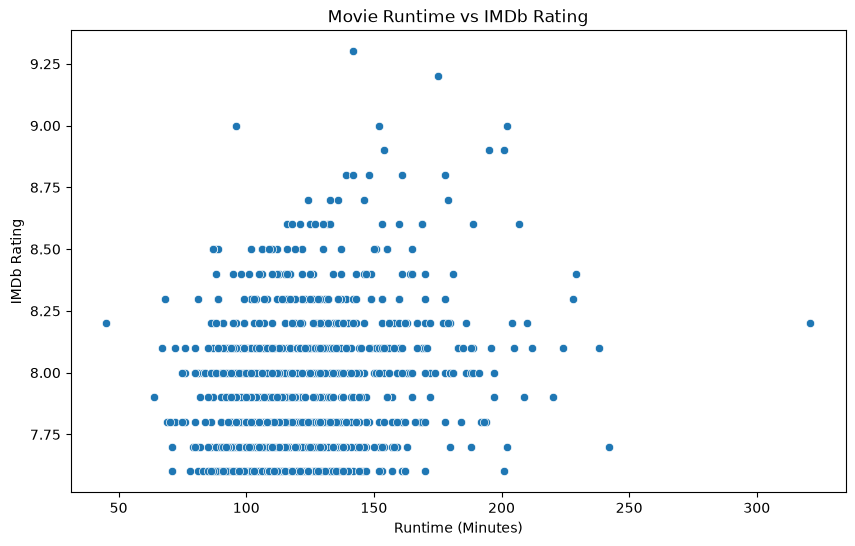

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Runtime',
    y='IMDB_Rating'
)

plt.title('Movie Runtime vs IMDb Rating')
plt.xlabel('Runtime (Minutes)')
plt.ylabel('IMDb Rating')
plt.show()

1. Movie Runtime vs IMDb Rating

The analysis shows no significant relationship between movie runtime and IMDb ratings. Longer movies do not necessarily receive higher ratings, suggesting that movie duration is not a reliable indicator of audience satisfaction.

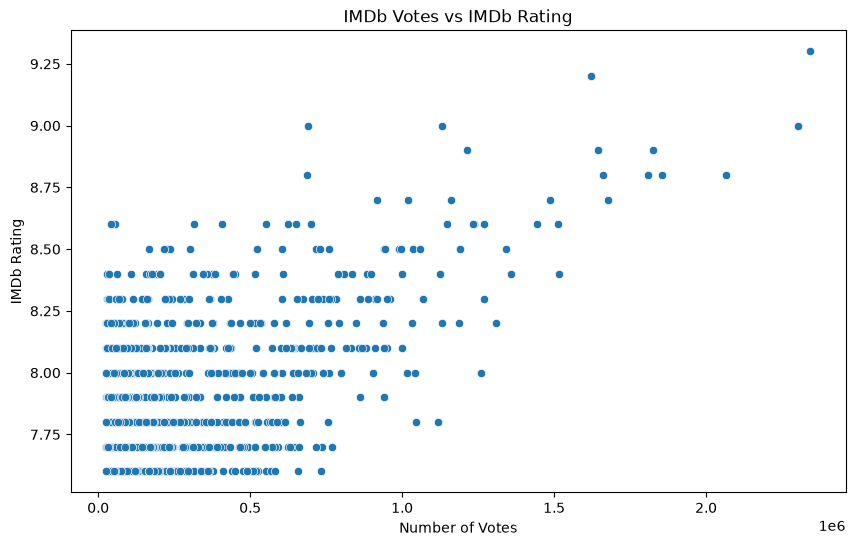

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='No_of_Votes',
    y='IMDB_Rating'
)

plt.title('IMDb Votes vs IMDb Rating')
plt.xlabel('Number of Votes')
plt.ylabel('IMDb Rating')
plt.show()

2. IMDb Votes vs IMDb Rating

A positive relationship can be observed between the number of votes and IMDb ratings. Movies with a larger number of votes include several highly rated titles. However, popularity does not necessarily guarantee a higher rating.

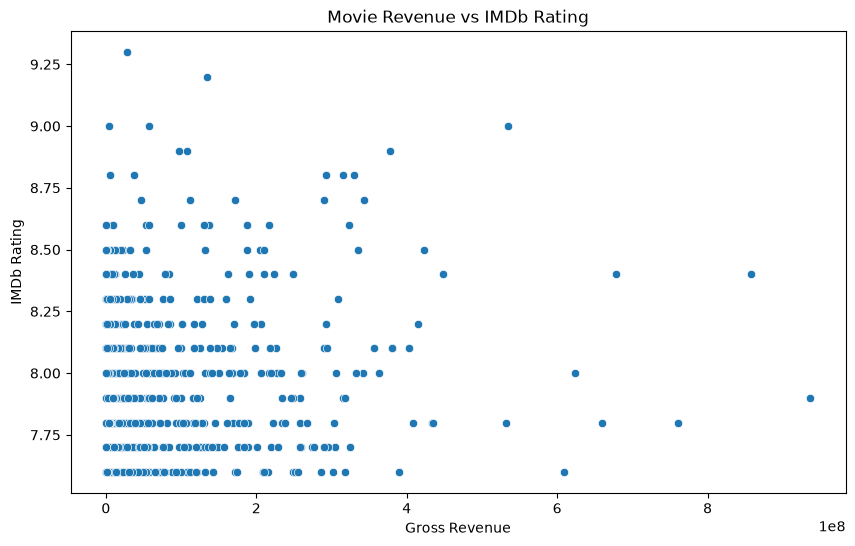

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Gross',
    y='IMDB_Rating'
)

plt.title('Movie Revenue vs IMDb Rating')
plt.xlabel('Gross Revenue')
plt.ylabel('IMDb Rating')
plt.show()

3. Movie Revenue vs IMDb Rating

The analysis indicates a weak relationship between movie revenue and IMDb ratings. Some highly rated movies generate relatively modest revenue, while commercially successful movies do not always achieve the highest ratings. This suggests that commercial success and audience ratings measure different aspects of a movie's performance.

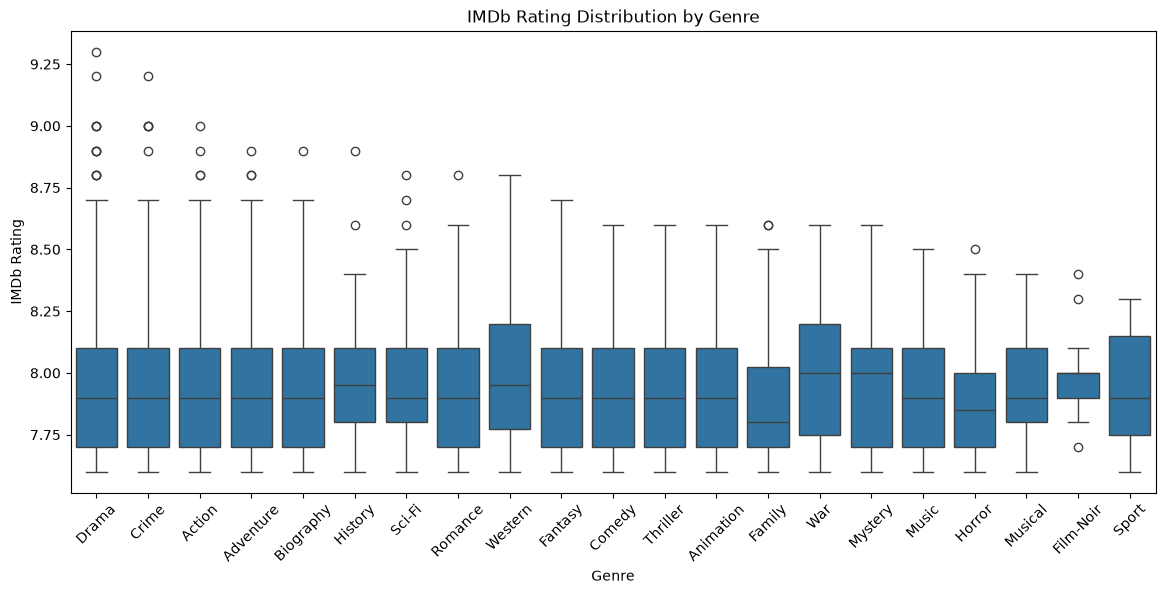

In [95]:

genre_df = df.copy()

genre_df['Genre'] = genre_df['Genre'].str.split(', ')
genre_df = genre_df.explode('Genre')

plt.figure(figsize=(14, 6))

sns.boxplot(data=genre_df, x='Genre', y='IMDB_Rating')

plt.title('IMDb Rating Distribution by Genre')
plt.xlabel('Genre')
plt.ylabel('IMDb Rating')
plt.xticks(rotation=45)

plt.show()

### Genre vs IMDb Rating

This box plot illustrates the distribution of IMDb ratings across different movie genres.

**Key Insights:**

1. **High-Rated Outliers:** Genres such as Drama, Crime, Action, Adventure, and Biography contain some unusually high-rated movies, with ratings approaching 9.3.

2. **Similar Median Ratings:** Most genres have median ratings around 7.9–8.0, suggesting that the typical IMDb ratings are relatively similar across different genres.

3. **Differences in Rating Distribution:** The box sizes and whiskers vary between genres, indicating differences in rating variability and consistency.

**Conclusion:**

Movie genre does not appear to create a major difference in the typical IMDb rating, as most genres have relatively close median values. However, some genres contain exceptional movies with significantly higher ratings.

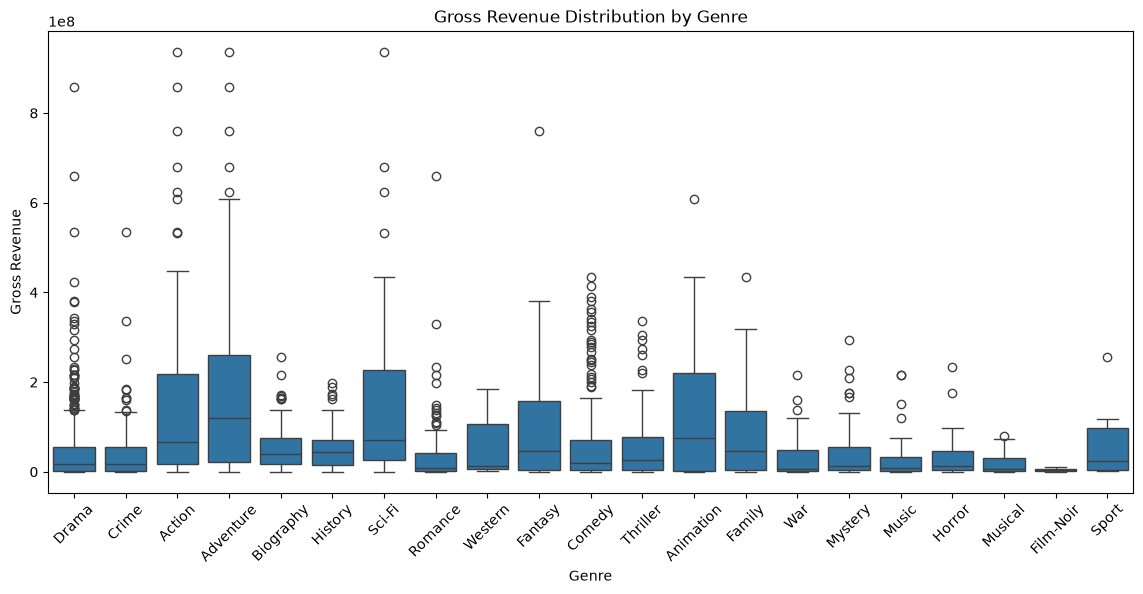

In [97]:
genre_df = df.copy().reset_index(drop=True)

genre_df['Genre'] = genre_df['Genre'].str.split(', ')

genre_df = genre_df.explode('Genre').reset_index(drop=True)

plt.figure(figsize=(14, 6))

sns.boxplot(data=genre_df, x='Genre', y='Gross')

plt.title('Gross Revenue Distribution by Genre')
plt.xlabel('Genre')
plt.ylabel('Gross Revenue')

plt.xticks(rotation=45)
plt.show()

### Genre vs Gross Revenue

**Conclusion:**

The box plot analysis reveals significant differences in gross revenue distributions across movie genres. Action, Adventure, and Sci-Fi contain some of the highest-grossing movies, with extreme outliers exceeding $800 million. These genres also show a wider spread in revenue, indicating greater variation in commercial performance.

In contrast, genres such as Film-Noir and Musical generally show lower revenue distributions within this dataset.

Overall, the analysis suggests that movie genre is associated with differences in box office performance, although high revenue is not guaranteed for every movie within a particular genre.

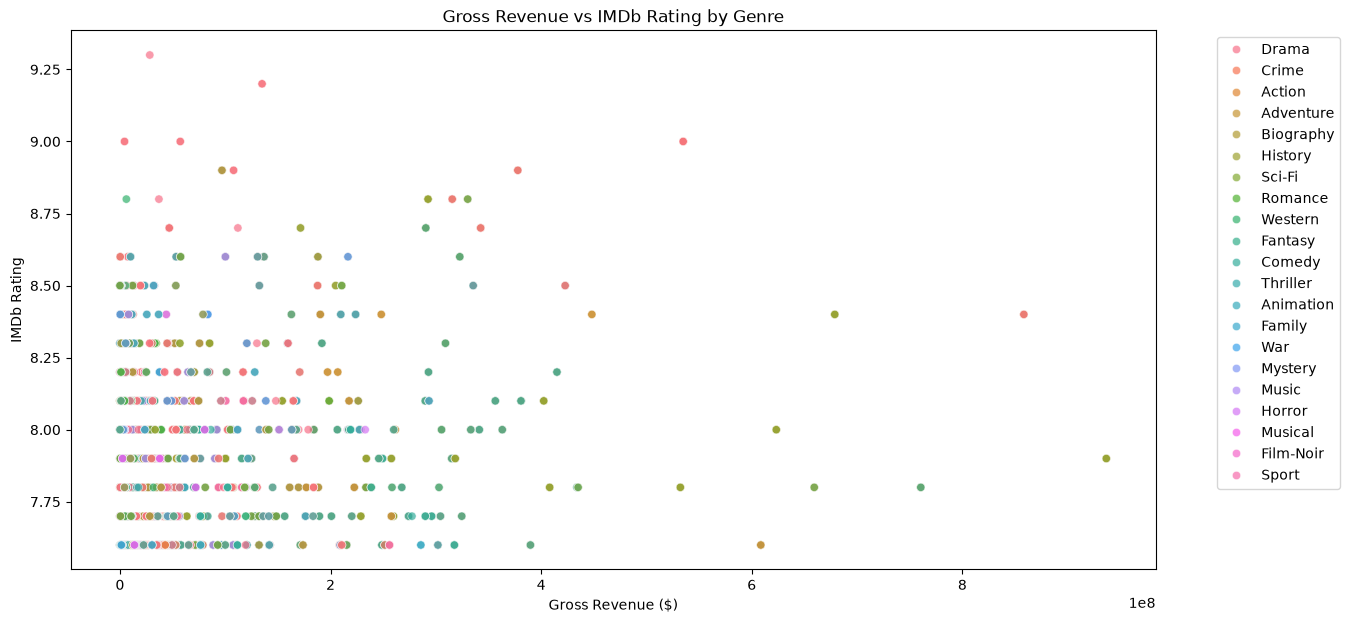

In [98]:
plt.figure(figsize=(14, 7))

sns.scatterplot(
    data=genre_df,
    x='Gross',
    y='IMDB_Rating',
    hue='Genre',
    alpha=0.7
)

plt.title('Gross Revenue vs IMDb Rating by Genre')
plt.xlabel('Gross Revenue ($)')
plt.ylabel('IMDb Rating')

plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()  

### Conclusion

The multivariate analysis reveals that high IMDb ratings do not necessarily correspond to high box-office revenues. The results highlight a distinction between critical acclaim and commercial success. Movies belonging to genres such as Drama and Crime tend to achieve exceptionally high ratings, even with relatively modest revenues. In contrast, commercially oriented genres such as Action, Adventure, and Sci-Fi dominate the highest revenue levels, often achieving substantial box-office success with comparatively moderate IMDb ratings.

Overall, these findings suggest that a movie's commercial performance is not solely determined by its critical reception, and that genre plays an important role in understanding the relationship between audience ratings and box-office revenue.

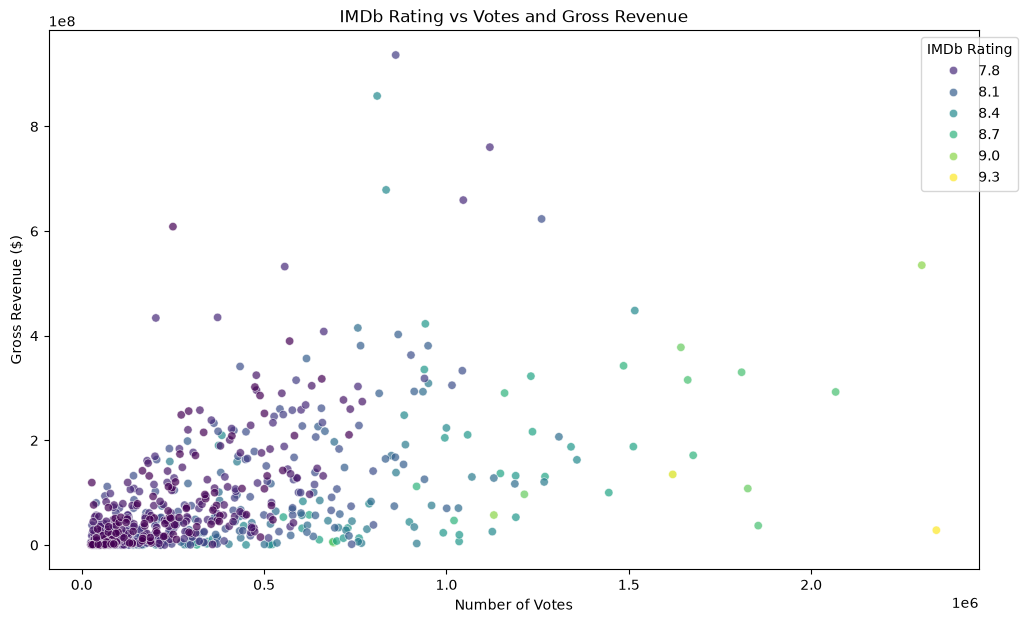

In [99]:
multi_df = df[['No_of_Votes', 'Gross', 'IMDB_Rating']].copy()

multi_df['Gross'] = pd.to_numeric(
    multi_df['Gross'].astype(str).str.replace(',', '', regex=False),
    errors='coerce'
)

multi_df = multi_df.dropna()

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=multi_df,
    x='No_of_Votes',
    y='Gross',
    hue='IMDB_Rating',
    palette='viridis',
    alpha=0.7
)

plt.title('IMDb Rating vs Votes and Gross Revenue')
plt.xlabel('Number of Votes')
plt.ylabel('Gross Revenue ($)')

plt.legend(title='IMDb Rating', bbox_to_anchor=(1.05, 1))
plt.show()

The multi-variable scatter plot analyzing IMDb votes against gross revenue, color-coded by IMDb ratings, reveals that elite critically acclaimed films (ratings $\ge 9.0$) strictly require massive audience engagement, clustering heavily at high vote volumes exceeding 1.5 million. However, these top-tier rated masterpieces do not necessarily capture the highest box-office revenues; instead, extreme financial blockbusters generating over $600M are predominantly associated with moderate-to-good rating tiers (7.8 to 8.4).  

# Key Findings

1. **IMDb Ratings:** Movie ratings show no strong relationship with runtime, indicating that longer movies are not necessarily rated higher.

2. **Movie Popularity:** The number of votes has a moderate positive correlation with IMDb ratings (0.49), suggesting that popular movies tend to receive slightly higher ratings.

3. **Revenue Analysis:** Gross revenue has a weak positive correlation with IMDb ratings (0.10), indicating that commercial success does not necessarily reflect critical or audience appreciation.

4. **Votes and Revenue:** A moderate positive correlation (0.57) exists between the number of votes and gross revenue, suggesting that more popular movies tend to generate higher revenue.

5. **Genre Analysis:** Action and Adventure movies dominate the highest revenue levels, while Drama and Crime movies frequently achieve high IMDb ratings.

6. **Director Performance:** Directors show different average rating patterns, reflecting variations in audience reception across their films.

7. **Rating Comparison:** IMDb ratings and Meta Scores provide different perspectives on movie quality, highlighting differences between audience opinions and critics' evaluations.

# Overall Project Conclusion

The analysis of the IMDb Movies Dataset revealed several interesting insights into the factors associated with movie ratings, popularity, and commercial success.

The findings indicate that movie popularity, measured by the number of votes, has a moderate positive relationship with both IMDb ratings and gross revenue. However, movie revenue has only a weak relationship with audience ratings, suggesting that financial success does not necessarily reflect audience appreciation.

Genre analysis also revealed differences between commercial and audience preferences, with Action and Adventure movies frequently appearing among the highest-grossing films, while Drama and Crime movies often achieve high audience ratings.

Furthermore, the analysis highlighted that movie characteristics, such as runtime, do not necessarily determine a film's rating or success.

Overall, the project demonstrates that movie success is influenced by multiple factors, and no single variable can fully explain a movie's popularity, audience reception, or financial performance.

# Recommendations

1. Movie producers should consider both audience preferences and critical feedback rather than focusing only on expected box-office revenue.

2. Production companies should analyze genre-specific market trends to better understand audience demand and commercial opportunities.

3. Movie evaluation systems should consider multiple factors, including audience ratings, popularity, and critical reviews.

4. Further analysis should investigate additional factors, such as production budgets, marketing strategies, and release dates, to better understand movie success.